# Robustness: other start years and inflation-adjusted values

Re-runs the Question 1, 2 and 4 metrics from 2017 and 2019 instead of 2015, drops Austin from the permits line, tries a
lagged permits window, and restates home values, rents and wages in constant dollars with CPI-U (FRED `CPIAUCSL`, the
`cpi` column). Rank agreement uses Spearman's correlation against the 2015 ranking.

Ratios (price-to-income, rent-to-wage) and growth gaps between two dollar series do not need deflating: dividing both
sides by the same CPI cancels out.

In [1]:
import common as c
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

## Question 1: price-to-income change by start year

In [2]:
p2i = pd.DataFrame({y: c.price_to_income_change(y).change for y in (2015, 2017, 2019)})
display(p2i.sort_values(2015, ascending=False).round(2))
p2i.corr(method="spearman")[2015].round(2).rename("spearman vs 2015")

,2015,2017,2019
metro,,,
Seattle,1.44,0.68,0.58
Nashville,1.39,0.89,0.82
Tampa,1.33,0.86,0.67
Charlotte,1.30,1.06,0.88
Orlando,1.09,0.70,0.55
Atlanta,1.06,0.82,0.64
Phoenix,1.03,0.72,0.55
Dallas-Fort Worth,0.90,0.41,0.35
Raleigh,0.74,0.57,0.55


2015    1.00
2017    0.75
2019    0.77
Name: spearman vs 2015, dtype: float64

## Question 2: permits against price growth, other windows

In [3]:
rows = {}
for label, permit_years, growth_years in [
    ("2016–2025 (base)", (2016, 2025), (2015, 2025)),
    ("2018–2025", (2018, 2025), (2017, 2025)),
    ("2020–2025", (2020, 2025), (2019, 2025)),
    ("permits 2016–2020, growth 2020–2025", (2016, 2020), (2020, 2025)),
]:
    d, fit = c.permits_vs_growth(permit_years, growth_years)
    rows[label] = fit
    if label.endswith("(base)"):
        x = d.drop("Austin")
        slope = np.polyfit(x.permits_per_1000, x.zhvi_growth, 1)[0]
        rows["2016–2025 without Austin"] = {
            "slope": slope,
            "r": np.corrcoef(x.permits_per_1000, x.zhvi_growth)[0, 1],
        }
pd.DataFrame(rows).T[["slope", "r"]].round(3)

,slope,r
2016–2025 (base),-0.031,-0.547
2016–2025 without Austin,-0.006,-0.104
2018–2025,-0.013,-0.327
2020–2025,-0.006,-0.244
"permits 2016–2020, growth 2020–2025",-0.006,-0.220


## Question 4: rent growth minus wage growth by start quarter

In [4]:
gaps = pd.DataFrame({s: c.rent_wage_gap(s).gap for s in ("2015Q1", "2017Q1", "2019Q1")})
display(
    (gaps.sort_values("2015Q1", ascending=False) * 100)
    .round(0)
    .astype(int)
    .add_suffix(" (pp)")
)
gaps.corr(method="spearman")["2015Q1"].round(2).rename("spearman vs 2015Q1")

,2015Q1 (pp),2017Q1 (pp),2019Q1 (pp)
metro,,,
Atlanta,28,21,7
Phoenix,26,16,4
Tampa,19,13,7
Charlotte,16,8,-2
Orlando,13,6,-1
Dallas-Fort Worth,1,-6,-8
Nashville,-5,-11,-11
Raleigh,-6,-6,-3
Denver,-16,-21,-20


2015Q1    1.00
2017Q1    0.99
2019Q1    0.95
Name: spearman vs 2015Q1, dtype: float64

## Inflation-adjusted growth since 2015

In [5]:
p = c.price_to_income_change(2015)
rw = c.rent_wage_gap("2015Q1")
real = pd.DataFrame(
    {
        "zhvi_nominal": p.latest_zhvi / p.start_zhvi - 1,
        "zhvi_real": p.latest_zhvi / p.start_zhvi * p.start_cpi / p.latest_cpi - 1,
        "rent_real": (1 + rw.rent_growth) / (1 + rw.inflation) - 1,
        "wage_real": (1 + rw.wage_growth) / (1 + rw.inflation) - 1,
    }
).sort_values("zhvi_real", ascending=False)
real["real_gap"] = real.rent_real - real.wage_real
print(
    f"CPI-U change, 2015 average to {c.LATEST_12M}: {(p.latest_cpi / p.start_cpi - 1).iloc[0]:+.1%}"
)
real.style.format("{:+.0%}")

CPI-U change, 2015 average to Oct 2025–Sep 2026: +39.5%


,zhvi_nominal,zhvi_real,rent_real,wage_real,real_gap
metro,,,,,
Charlotte,+119%,+57%,+23%,+12%,+11%
Tampa,+118%,+56%,+35%,+22%,+14%
Nashville,+115%,+54%,+13%,+17%,-4%
Seattle,+111%,+51%,+18%,+35%,-18%
Atlanta,+110%,+51%,+30%,+10%,+20%
Orlando,+107%,+48%,+25%,+16%,+9%
Phoenix,+106%,+48%,+33%,+14%,+19%
Dallas-Fort Worth,+94%,+39%,+11%,+10%,+0%
Raleigh,+91%,+37%,+11%,+16%,-5%


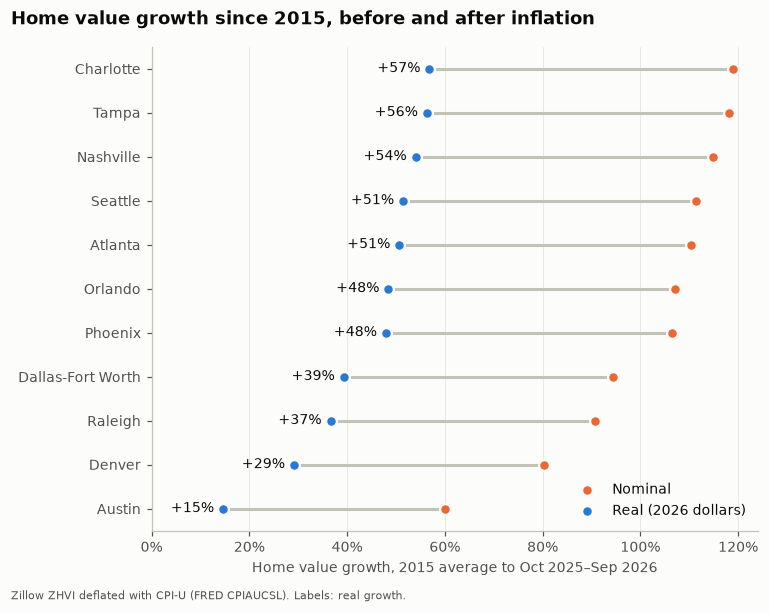

In [6]:
import matplotlib.pyplot as plt

r = real.sort_values("zhvi_real")
fig, ax = plt.subplots(figsize=(7, 0.38 * len(r) + 1.2))
y = range(len(r))
ax.hlines(y, r.zhvi_real, r.zhvi_nominal, color=c.MUTED, lw=2)
ax.scatter(
    r.zhvi_nominal,
    y,
    s=50,
    color=c.ORANGE,
    edgecolor=c.SURFACE,
    linewidth=1.5,
    zorder=3,
    label="Nominal",
)
ax.scatter(
    r.zhvi_real,
    y,
    s=50,
    color=c.BLUE,
    edgecolor=c.SURFACE,
    linewidth=1.5,
    zorder=3,
    label="Real (2026 dollars)",
)
for i, (m, row) in enumerate(r.iterrows()):
    ax.annotate(
        f"{row.zhvi_real:+.0%}",
        (row.zhvi_real, i),
        xytext=(-6, 0),
        textcoords="offset points",
        ha="right",
        va="center",
        color=c.INK,
    )
ax.set_yticks(list(y), r.index)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel(f"Home value growth, 2015 average to {c.LATEST_12M}")
ax.set_xlim(0, None)
ax.legend(loc="lower right", frameon=False)
c.save(
    fig,
    "robustness_real_vs_nominal",
    "Home value growth since 2015, before and after inflation",
    "Zillow ZHVI deflated with CPI-U (FRED CPIAUCSL). Labels: real growth.",
)

## Summary

In [7]:
rho_p2i = p2i.corr(method="spearman")[2015]
rho_gap = gaps.corr(method="spearman")["2015Q1"]
print(
    f"Q1 ranking vs 2015 start: Spearman {rho_p2i[2017]:.2f} (2017), {rho_p2i[2019]:.2f} (2019)."
)
print(
    "Q2 slope and r by window:",
    {
        k: (round(float(v["slope"]), 3), round(float(v["r"]), 2))
        for k, v in rows.items()
    },
)
print(
    f"Q4 ranking vs 2015 Q1 start: Spearman {rho_gap['2017Q1']:.2f} (2017 Q1), {rho_gap['2019Q1']:.2f} (2019 Q1)."
)
print(
    f"Real home value growth since 2015: {real.zhvi_real.max():+.0%} ({real.zhvi_real.idxmax()}) to "
    f"{real.zhvi_real.min():+.0%} ({real.zhvi_real.idxmin()})."
)

Q1 ranking vs 2015 start: Spearman 0.75 (2017), 0.77 (2019).
Q2 slope and r by window: {'2016–2025 (base)': (-0.031, -0.55), '2016–2025 without Austin': (-0.006, -0.1), '2018–2025': (-0.013, -0.33), '2020–2025': (-0.006, -0.24), 'permits 2016–2020, growth 2020–2025': (-0.006, -0.22)}
Q4 ranking vs 2015 Q1 start: Spearman 0.99 (2017 Q1), 0.95 (2019 Q1).
Real home value growth since 2015: +57% (Charlotte) to +15% (Austin).
